<a href="https://colab.research.google.com/github/saadat309/Digiskills-Excercises/blob/main/Ai_with_python_Exercise_4_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 4 - Mushroom Classification with CNN and RNN

**Course:** Artificial Intelligence Using Python (AIP301)  
**Dataset:** Mushroom/Fungi Classification (`mushrooms.csv`)

This notebook completes the classification, comparison, visualization, and text-tokenization tasks in the exercise. It uses TensorFlow/Keras for the neural networks and Hugging Face Transformers for tokenization. The supplied CSV is expected in the same folder as this notebook.

> The provided `exercise_text.json` is saved beside this notebook and is loaded in Part 2.


## 1. Install and import dependencies

If a package is missing, install the packages in the first code cell, then restart the notebook kernel and run all cells. TensorFlow can take a few minutes to install.

In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)


TensorFlow: 2.21.0
NumPy: 2.1.3


## 2. Load and explore the data

The `?` values in `stalk-root` are retained as their own categorical value. This avoids silently discarding rows and lets the model learn from the missingness pattern.

In [ ]:
DATA_PATH = Path("mushrooms.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Place mushrooms.csv in the same folder as this notebook.")

data = pd.read_csv(DATA_PATH, dtype="string")
print("Shape:", data.shape)
display(data.head())
print("\nColumn types:")
print(data.dtypes)
print("\nMissing values:")
print(data.isna().sum().sort_values(ascending=False).head())
print("\nTarget counts:")
print(data["class"].value_counts())
print("\nUnique category counts:")
print(data.nunique().sort_values(ascending=False))


Shape: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g



Column types:
class                       string[python]
cap-shape                   string[python]
cap-surface                 string[python]
cap-color                   string[python]
bruises                     string[python]
odor                        string[python]
gill-attachment             string[python]
gill-spacing                string[python]
gill-size                   string[python]
gill-color                  string[python]
stalk-shape                 string[python]
stalk-root                  string[python]
stalk-surface-above-ring    string[python]
stalk-surface-below-ring    string[python]
stalk-color-above-ring      string[python]
stalk-color-below-ring      string[python]
veil-type                   string[python]
veil-color                  string[python]
ring-number                 string[python]
ring-type                   string[python]
spore-print-color           string[python]
population                  string[python]
habitat                     string[pyth

## 3. Prepare features and create a stratified 70/30 split

All input columns are categorical. One-hot encoding represents categories without imposing a false numeric ranking. The encoder is fitted only on training rows to avoid leakage. For Keras, the encoded feature vector is reshaped to `(number_of_encoded_features, 1)`: each binary indicator is one step in the feature sequence. This allows both Conv1D and recurrent layers to receive a 3D input tensor.

In [ ]:
X_raw = data.drop(columns="class").fillna("__MISSING__").astype(str)
y_text = data["class"].astype(str)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text).astype("int32")
print("Class mapping:", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.30, random_state=SEED, stratify=y
)
try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
except TypeError:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=False, dtype=np.float32)

X_train_flat = onehot.fit_transform(X_train_raw)
X_test_flat = onehot.transform(X_test_raw)
X_train = X_train_flat[..., np.newaxis]
X_test = X_test_flat[..., np.newaxis]
y_train = np.asarray(y_train, dtype=np.int32)
y_test = np.asarray(y_test, dtype=np.int32)

print("Training rows:", X_train.shape[0], "| Test rows:", X_test.shape[0])
print("Encoded features:", X_train_flat.shape[1])
print("CNN/RNN input shape:", X_train.shape[1:])


Class mapping: {'e': np.int64(0), 'p': np.int64(1)}
Training rows: 5686 | Test rows: 2438
Encoded features: 117
CNN/RNN input shape: (117, 1)


## 4. Build, visualize, train, and evaluate the CNN

The CNN uses the required **batch size 30**, **10 epochs**, and **Adam** optimizer. The output layer has one sigmoid unit because this is a binary classification task.

In [ ]:
cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1], 1)),
    tf.keras.layers.Conv1D(32, kernel_size=3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling1D(pool_size=2),
    tf.keras.layers.Conv1D(64, kernel_size=3, padding="same", activation="relu"),
    tf.keras.layers.GlobalMaxPooling1D(),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(1, activation="sigmoid")
], name="CNN")
cnn.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
cnn.summary()


Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 117, 32)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 58, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 58, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,449 (33.00 KB)

 Trainable params: 8,449 (33.00 KB)

 Non-trainable params: 0 (0.00 B)

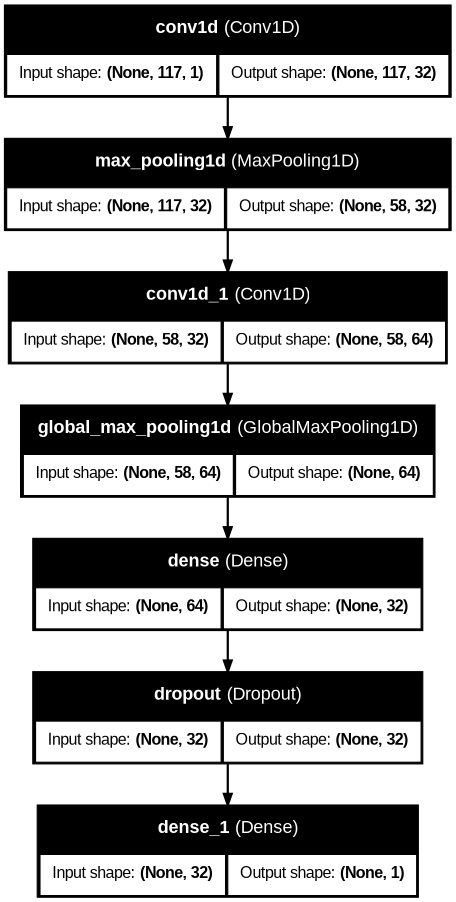

In [ ]:
tf.keras.utils.plot_model(cnn, show_shapes=True, show_layer_names=True, dpi=80)


In [ ]:
cnn_history = cnn.fit(
    X_train, y_train,
    validation_split=0.10,
    epochs=10,
    batch_size=30,
    verbose=1
)


Epoch 1/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.7659 - loss: 0.5587 - val_accuracy: 0.9244 - val_loss: 0.2800
Epoch 2/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9216 - loss: 0.2280 - val_accuracy: 0.9684 - val_loss: 0.1292
Epoch 3/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9513 - loss: 0.1564 - val_accuracy: 0.9842 - val_loss: 0.0859
Epoch 4/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9631 - loss: 0.1328 - val_accuracy: 0.9859 - val_loss: 0.0678
Epoch 5/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9701 - loss: 0.1141 - val_accuracy: 0.9859 - val_loss: 0.0563
Epoch 6/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9742 - loss: 0.0995 - val_accuracy: 0.9912 - val_loss: 0.0500
Epoch 7/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9760 - loss: 0.0920 - val_accuracy: 0.9912 - val_loss: 0.0429
Epoch 8/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9764 - loss: 0.0863 - val_accuracy: 

## 5. Build, visualize, train, and evaluate the RNN

The RNN uses the required **batch size 40**, **20 epochs**, and **RMSprop** optimizer. A bidirectional LSTM reads the encoded feature-indicator sequence in both directions.

In [ ]:
rnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1], 1)),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(1, activation="sigmoid")
], name="RNN")
rnn.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["accuracy"])
rnn.summary()


Model: "RNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 64)             │         8,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,817 (42.25 KB)

 Trainable params: 10,817 (42.25 KB)

 Non-trainable params: 0 (0.00 B)

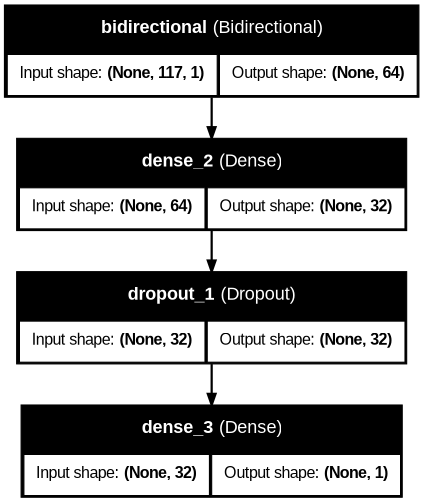

In [ ]:
tf.keras.utils.plot_model(rnn, show_shapes=True, show_layer_names=True, dpi=80)


In [ ]:
rnn_history = rnn.fit(
    X_train, y_train,
    validation_split=0.10,
    epochs=20,
    batch_size=40,
    verbose=1
)


Epoch 1/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 17s 70ms/step - accuracy: 0.5626 - loss: 0.6848 - val_accuracy: 0.6714 - val_loss: 0.6450
Epoch 2/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 8s 61ms/step - accuracy: 0.7174 - loss: 0.5835 - val_accuracy: 0.7680 - val_loss: 0.5061
Epoch 3/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.7885 - loss: 0.4771 - val_accuracy: 0.7645 - val_loss: 0.4823
Epoch 4/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 11s 59ms/step - accuracy: 0.8399 - loss: 0.4070 - val_accuracy: 0.8735 - val_loss: 0.3370
Epoch 5/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 8s 61ms/step - accuracy: 0.8620 - loss: 0.3671 - val_accuracy: 0.8752 - val_loss: 0.3050
Epoch 6/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 7s 51ms/step - accuracy: 0.8708 - loss: 0.3446 - val_accuracy: 0.8963 - val_loss: 0.2807
Epoch 7/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 11s 59ms/step - accuracy: 0.8728 - loss: 0.3286 - val_accuracy: 0.9051 - val_loss: 0.2617
Epoch 8/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 11s 62ms/step - accuracy: 0.8880 - loss: 0.3063 - val_

## 6. Plot training performance

These plots show training and validation loss and accuracy over each model’s required number of epochs.

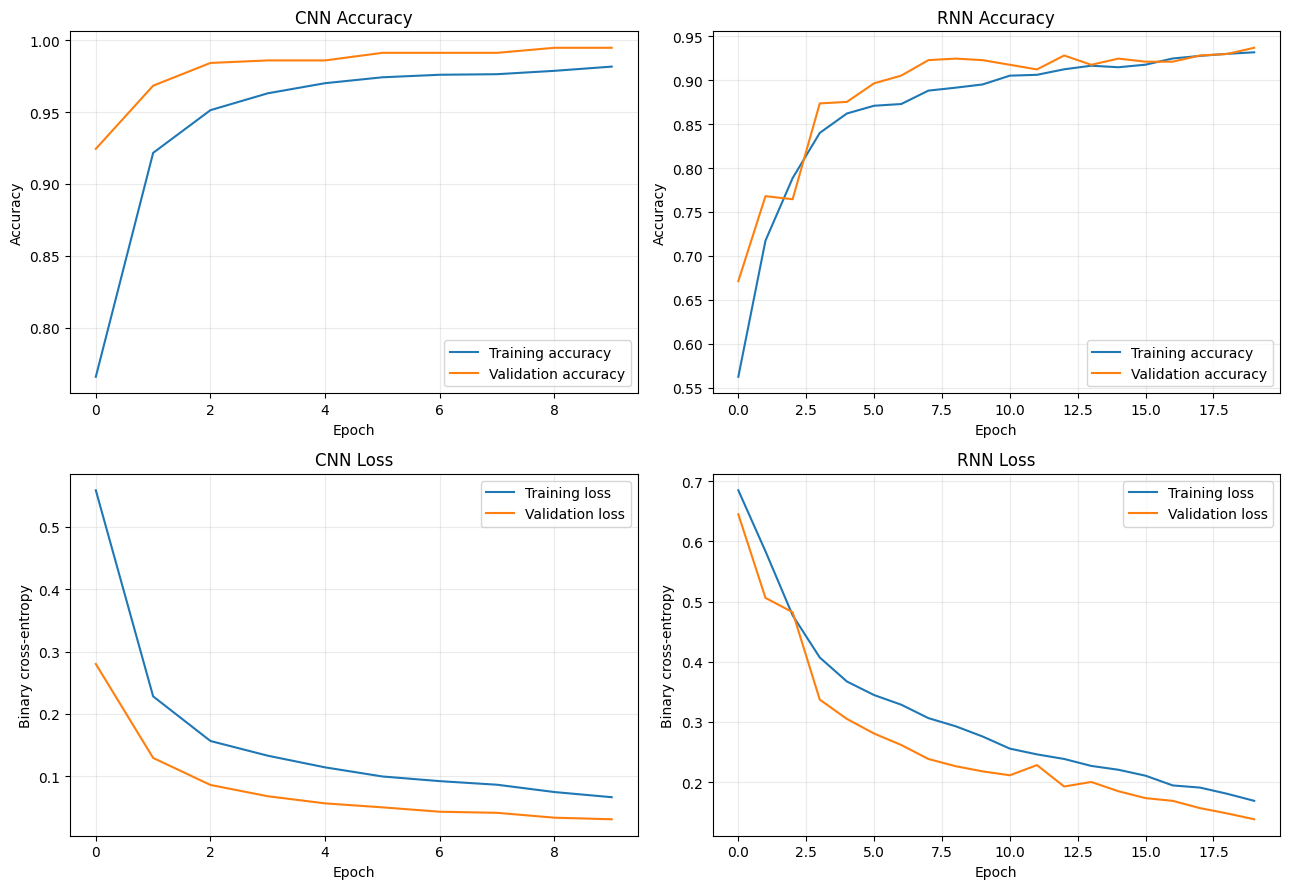

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, history, title in [
    (axes[0, 0], cnn_history, "CNN"),
    (axes[0, 1], rnn_history, "RNN")
]:
    ax.plot(history.history["accuracy"], label="Training accuracy")
    ax.plot(history.history["val_accuracy"], label="Validation accuracy")
    ax.set(title=f"{title} Accuracy", xlabel="Epoch", ylabel="Accuracy")
    ax.legend(); ax.grid(alpha=.25)
for ax, history, title in [
    (axes[1, 0], cnn_history, "CNN"),
    (axes[1, 1], rnn_history, "RNN")
]:
    ax.plot(history.history["loss"], label="Training loss")
    ax.plot(history.history["val_loss"], label="Validation loss")
    ax.set(title=f"{title} Loss", xlabel="Epoch", ylabel="Binary cross-entropy")
    ax.legend(); ax.grid(alpha=.25)
plt.tight_layout()
plt.show()


7. Generate test predictions and compare accuracy

A sigmoid output is converted to a class using a threshold of 0.5. The table reports the requested held-out test accuracy and each model’s final training accuracy.

In [ ]:
cnn_prob = cnn.predict(X_test, verbose=0).ravel()
rnn_prob = rnn.predict(X_test, verbose=0).ravel()
cnn_pred = (cnn_prob >= 0.5).astype(int)
rnn_pred = (rnn_prob >= 0.5).astype(int)

cnn_test_accuracy = accuracy_score(y_test, cnn_pred)
rnn_test_accuracy = accuracy_score(y_test, rnn_pred)
comparison = pd.DataFrame({
    "Model": ["CNN", "RNN"],
    "Optimizer": ["Adam", "RMSprop"],
    "Batch size": [30, 40],
    "Epochs": [10, 20],
    "Final training accuracy": [cnn_history.history["accuracy"][-1], rnn_history.history["accuracy"][-1]],
    "Test accuracy": [cnn_test_accuracy, rnn_test_accuracy]
})
display(comparison.style.format({"Final training accuracy": "{:.4f}", "Test accuracy": "{:.4f}"}))


,Model,Optimizer,Batch size,Epochs,Final training accuracy,Test accuracy
0,CNN,Adam,30,10,0.9816,0.9889
1,RNN,RMSprop,40,20,0.9316,0.9422


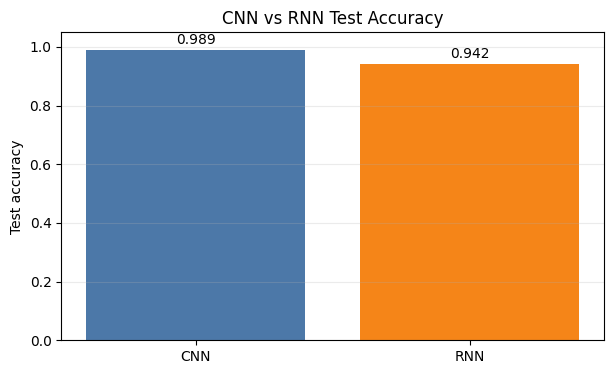

Higher test accuracy: CNN
Recommendation: choose the model with the higher held-out test accuracy shown above.


In [ ]:
plt.figure(figsize=(7, 4))
plt.bar(comparison["Model"], comparison["Test accuracy"], color=["#4C78A8", "#F58518"])
plt.ylim(0, 1.05)
plt.ylabel("Test accuracy")
plt.title("CNN vs RNN Test Accuracy")
for i, value in enumerate(comparison["Test accuracy"]):
    plt.text(i, value + 0.02, f"{value:.3f}", ha="center")
plt.grid(axis="y", alpha=.25)
plt.show()

best_model = "CNN" if cnn_test_accuracy > rnn_test_accuracy else "RNN" if rnn_test_accuracy > cnn_test_accuracy else "Tie"
print(f"Higher test accuracy: {best_model}")
print("Recommendation: choose the model with the higher held-out test accuracy shown above.")


## 8. Confusion matrices and classification reports

Rows in each confusion matrix are the true classes; columns are predicted classes. Precision, recall, and F1-score are reported for each mushroom class.

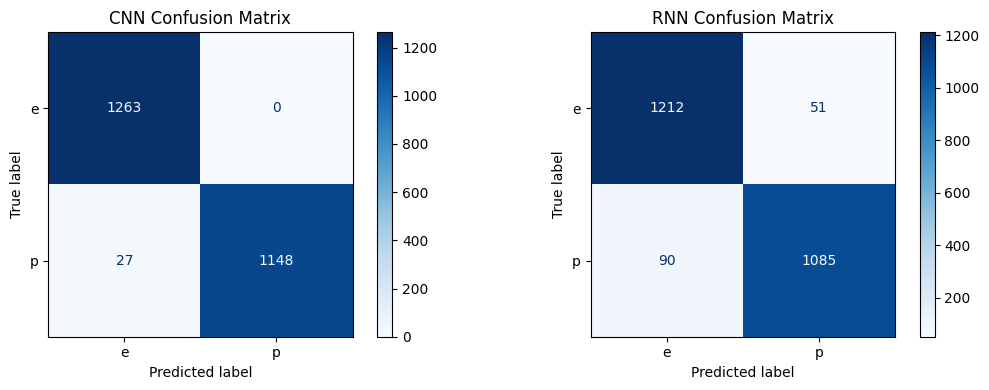

CNN Classification Report
              precision    recall  f1-score   support

           e     0.9791    1.0000    0.9894      1263
           p     1.0000    0.9770    0.9884      1175

    accuracy                         0.9889      2438
   macro avg     0.9895    0.9885    0.9889      2438
weighted avg     0.9892    0.9889    0.9889      2438

RNN Classification Report
              precision    recall  f1-score   support

           e     0.9309    0.9596    0.9450      1263
           p     0.9551    0.9234    0.9390      1175

    accuracy                         0.9422      2438
   macro avg     0.9430    0.9415    0.9420      2438
weighted avg     0.9426    0.9422    0.9421      2438



In [ ]:
class_names = [str(v) for v in label_encoder.classes_]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, title in [(axes[0], cnn_pred, "CNN Confusion Matrix"),
                        (axes[1], rnn_pred, "RNN Confusion Matrix")]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=class_names, cmap="Blues", values_format="d", ax=ax
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

print("CNN Classification Report")
print(classification_report(y_test, cnn_pred, target_names=class_names, digits=4, zero_division=0))
print("RNN Classification Report")
print(classification_report(y_test, rnn_pred, target_names=class_names, digits=4, zero_division=0))


## 9. Part 2 - Tokenize `exercise_text.json` with Hugging Face

The supplied `exercise_text.json` file is loaded from the notebook folder. The text is tokenized using Hugging Face Transformers and the pretrained `bert-base-uncased` tokenizer. Its tokenizer files may be downloaded on the first run.


In [ ]:
from transformers import AutoTokenizer

JSON_PATH = Path("exercise_text.json")
if not JSON_PATH.exists():
    raise FileNotFoundError(
        "exercise_text.json was not supplied with the exercise materials. "
        "Download it from the LMS and place it beside this notebook, then rerun this section."
    )

with JSON_PATH.open("r", encoding="utf-8") as f:
    json_data = json.load(f)

def collect_text_values(value):
    """Collect non-empty strings from common JSON object/list structures."""
    if isinstance(value, str):
        text = value.strip()
        return [text] if text else []
    if isinstance(value, list):
        return [text for item in value for text in collect_text_values(item)]
    if isinstance(value, dict):

        preferred = [v for k, v in value.items()
                     if any(term in k.lower() for term in ("text", "sentence", "content"))]
        values = preferred if preferred else list(value.values())
        return [text for item in values for text in collect_text_values(item)]
    return []

texts = collect_text_values(json_data)
if not texts:
    raise ValueError("No non-empty text strings were found in exercise_text.json.")

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
tokenized = tokenizer(texts, padding=True, truncation=True)
print("Number of text samples:", len(texts))
print("First text:", texts[0])
print("Tokens:", tokenizer.convert_ids_to_tokens(tokenized["input_ids"][0]))
print("Input IDs:", tokenized["input_ids"][0])
print("Attention mask:", tokenized["attention_mask"][0])


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Number of text samples: 1
First text: In this exercise, you are required to Apply and evaluate CNN, ANN, and RNN models Compare their performance and identify the model that achieves the highest accuracy for image classification using the **Iris Flowers dataset**. You will load and preprocess image data, design a multi-layer CNN architecture using TensorFlow/Keras, and train the model to recognize different object categories. After training, you will evaluate the model's performance on unseen test data and visualize the training loss across epochs. The objective of this exercise is to provide hands-on experience with **Deep Learning and Computer Vision**, enabling you to understand the complete workflow of an image classification project. Also solve the Large Language Models (LLMs) Architecture & Work. And Using LLMs with LangChain, passing prompts programmatically.
Tokens: ['[CLS]', 'in', 'this', 'exercise', ',', 'you', 'are', 'required', 'to', 'apply', 'and', 'evaluate', 'cnn', ',', 

## Conclusion

Run all cells to train and evaluate both models. The comparison table and bar chart give test accuracy; the printed result identifies the model with the higher score. Confusion matrices and classification reports show the errors and per-class results. The final section tokenizes the supplied `exercise_text.json` file with Hugging Face Transformers.
